## Setup

We begin by importing some packages used throughout the notebook and setting up our plotting environment.

In [51]:
import torch #
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import time
from skorch import NeuralNetClassifier
import torchvision.transforms as transforms
from torch.utils.data import DataLoader
import torchvision.datasets as datasets

In [189]:
import pandas as pd
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import pickle

from tensorflow.keras.preprocessing.image import ImageDataGenerator

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau


from scikeras.wrappers import KerasClassifier
from sklearn.model_selection import train_test_split, GridSearchCV
from keras_tuner import Hyperband

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import precision_score, recall_score, f1_score, classification_report

# Set up inline plotting and configure figure/axis labels
%matplotlib inline
mpl.rc('axes', labelsize=14)
mpl.rc('xtick', labelsize=12)
mpl.rc('ytick', labelsize=12)

# Set random seeds for reproducibility
np.random.seed(42)
keras.backend.clear_session()
tf.random.set_seed(42)

# Utility function to plot each label
def plot_examples(data, labels):
    # Get unique labels
    unique_labels = np.unique(labels)
    
    # Set up 8x8 grid for the 62 unique labels
    n_rows = 8  
    n_cols = 8  
    
    plt.figure(figsize=(n_cols * 1.5, n_rows * 1.5))
    
    for i, label in enumerate(unique_labels):
        # Find the first image corresponding to each unique label
        idx = np.where(labels == label)[0][0]
        
        # Plot each image
        plt.subplot(n_rows, n_cols, i + 1)
        plt.imshow(data[idx].squeeze(), cmap="gray")
        plt.title(f"Label: {label}")
        plt.axis("off")
    
    plt.tight_layout()
    plt.show()

## Loading the Data:

In [138]:
# Load the training and test datasets
with open('emnist_train.pkl', 'rb') as f:
    emnist_train = pickle.load(f)

with open('emnist_test.pkl', 'rb') as f:
    emnist_test = pickle.load(f)

# Extract data and labels
X_train_full = emnist_train['data']
y_train_full = emnist_train['labels']

X_test = emnist_test['data']
y_test = emnist_test['labels']

In [4]:
#Load the train and test data

train_images = torch.tensor(emnist_train['data'], dtype=torch.float32) / 255.0  # Normalize the images
train_labels = torch.tensor(emnist_train['labels'], dtype=torch.long)

with open('emnist_test.pkl', 'rb') as f:
    test_data = pickle.load(f)
test_images = torch.tensor(emnist_test['data'], dtype=torch.float32) / 255.0
test_labels = torch.tensor(emnist_test['labels'], dtype=torch.long)

Now I will be checking if the data has been extracted correctly by checking the shapes and the datatypes of the training and test data

Training data shape: (100000, 28, 28)
Training labels shape: (100000,)
Test data shape: (20000, 28, 28)
Test labels shape: (20000,)
Data type of X_train_full: uint8
Data type of y_train_full: int64


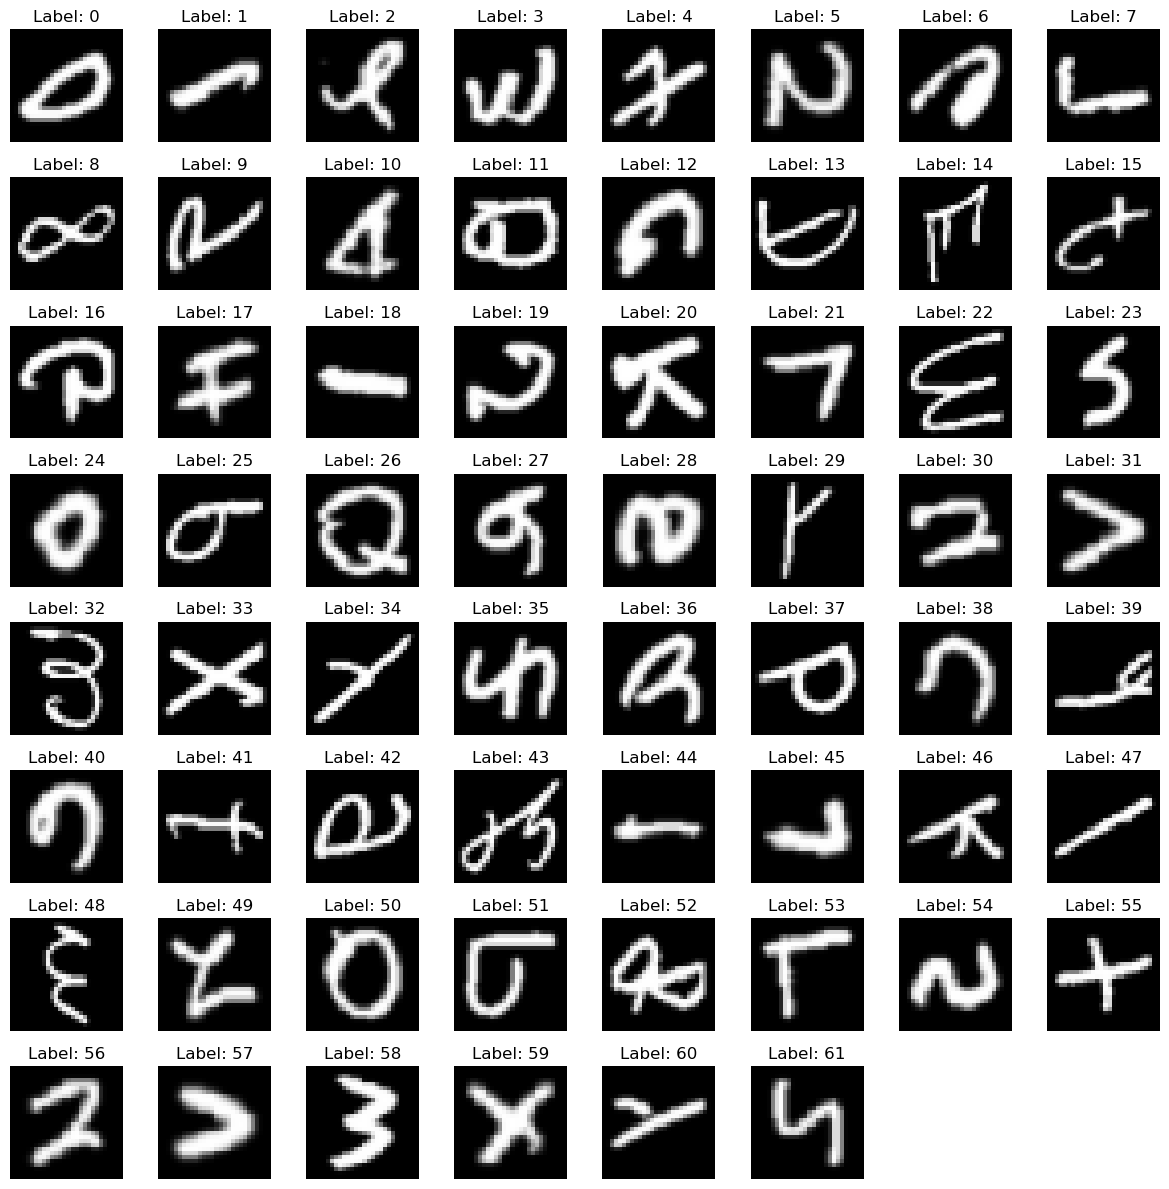

In [141]:
# Check the shapes of the training and test data
print(f"Training data shape: {X_train_full.shape}")
print(f"Training labels shape: {y_train_full.shape}")
print(f"Test data shape: {X_test.shape}")
print(f"Test labels shape: {y_test.shape}")

# Check the data types
print(f"Data type of X_train_full: {X_train_full.dtype}")
print(f"Data type of y_train_full: {y_train_full.dtype}")

# Display some sample images and their corresponding labels
plot_examples(X_train_full, y_train_full)

# Data exploration

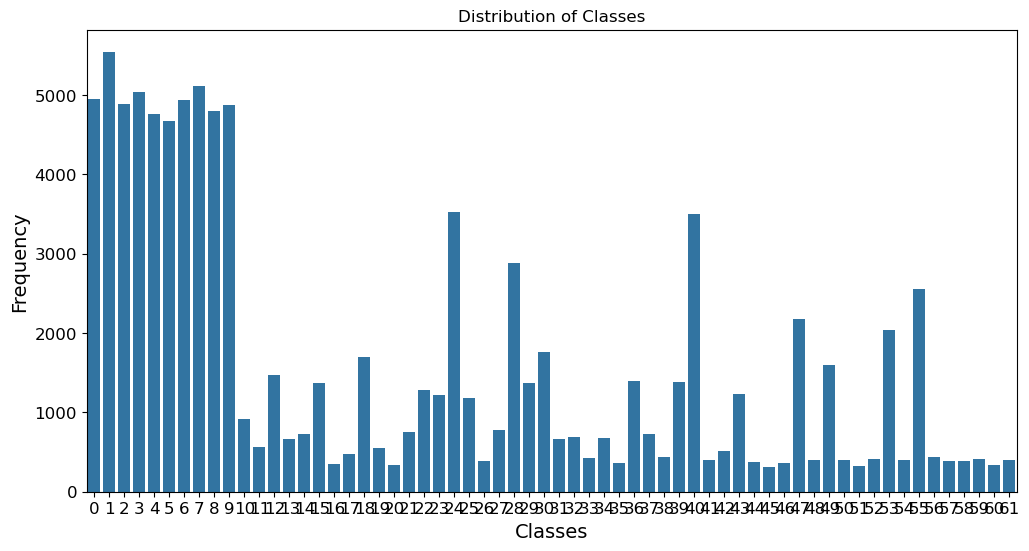

In [144]:
import seaborn as sns

plt.figure(figsize=(12, 6))
sns.countplot(x=y_train_full)
plt.title('Distribution of Classes')
plt.xlabel('Classes')
plt.ylabel('Frequency')
plt.show()

# Data preprocessing

### Normalising data

In [148]:
# Normalize the data to the range 0-1 (since the pixel values are between 0 and 255)
X_train_full = X_train_full / 255
X_test = X_test / 255

In [150]:
#Using the holdout method to split the data into training and validation sets (90% train, 10% validation)
X_train, X_valid, y_train, y_valid = train_test_split(X_train_full, y_train_full, train_size=0.9, random_state=21)

### Adding extra dimension for CNN

In [153]:
# Assuming your images are in X_train_full and X_test
X_train_expanded = np.expand_dims(X_train, axis=-1)  # Add channel dimension
X_valid_expanded = np.expand_dims(X_valid, axis=-1)  # Add channel dimension
X_test_expanded = np.expand_dims(X_test, axis=-1)  # Add channel dimension

# Check the new shapes
print("Expanded training data shape:", X_train_expanded.shape)  # Should be (90000, 28, 28, 1)
print("Expanded validation data shape:", X_valid_expanded.shape)  # Should be (10000, 28, 28, 1)
print("Expanded test data shape:", X_test_expanded.shape)  # Should be (20000, 28, 28, 1)

Expanded training data shape: (90000, 28, 28, 1)
Expanded validation data shape: (10000, 28, 28, 1)
Expanded test data shape: (20000, 28, 28, 1)


### Data Augmentation

In [156]:
# Define the data augmentation
datagen = ImageDataGenerator(
    rotation_range=90,        # Handle rotations up to 90 degrees
    width_shift_range=0.1,    # Random horizontal shift
    height_shift_range=0.1,   # Random vertical shift
    shear_range=0.2,          # Shear transformation
    zoom_range=0.2,           # Zoom in and out
    horizontal_flip=True,     # Flip images horizontally
    fill_mode='nearest'       # Filling empty pixels after transformations
)

# Apply the augmentation to your training dataset
datagen.fit(X_train_expanded)

In [5]:
# Define data augmentation including rotation
transform = transforms.Compose([
    transforms.RandomRotation(degrees=15),  # Rotate images by up to 15 degrees
    transforms.ToTensor()  # Convert images to tensors
])

### Reshaep the image(for LeNet-5 only)

In [6]:
# Reshape the images to remove the extra channel dimension (1, 28, 28)
train_images = train_images.reshape(-1, 1, 28, 28)
test_images = test_images.reshape(-1, 1, 28, 28)

### Create DataLoader for training and test

In [7]:
# Create DataLoader for training and test sets
batch_size = 64
train_loader = DataLoader(TensorDataset(train_images, train_labels), batch_size=batch_size, shuffle=True)
test_loader = DataLoader(TensorDataset(test_images, test_labels), batch_size=batch_size, shuffle=False)
# Load dataset with the transformation
train_loader.dataset.transform= transform

# Modeling 1 [CNN]

In [158]:
# Define the CNN model
model = keras.Sequential([
    # Specify the input shape
    keras.Input(shape=(28, 28, 1)),
    
    # Conv and pool block 1 with batch normalization
    keras.layers.Conv2D(32, kernel_size=(3, 3), activation="relu", padding='same'),
    keras.layers.BatchNormalization(),  
    keras.layers.MaxPooling2D(pool_size=(2, 2)),
    
    # Conv and pool block 2 with batch normalization
    keras.layers.Conv2D(64, kernel_size=(3, 3), activation="relu", padding='same'),
    keras.layers.BatchNormalization(),  
    keras.layers.MaxPooling2D(pool_size=(2, 2)),
    
    # Conv and pool block 3 with batch normalization
    keras.layers.Conv2D(128, kernel_size=(3, 3), activation="relu", padding='same'),
    keras.layers.BatchNormalization(),  
    keras.layers.MaxPooling2D(pool_size=(2, 2)),
    
    # Additional Conv and pool block 4 with batch normalization
    keras.layers.Conv2D(256, kernel_size=(3, 3), activation="relu", padding='same'),
    keras.layers.BatchNormalization(),  
    keras.layers.MaxPooling2D(pool_size=(2, 2)),
    
    # Flatten and classify using dense output layer
    keras.layers.Flatten(),
    keras.layers.Dropout(0.5),  # Increased dropout to counter potential overfitting
    keras.layers.Dense(128, activation="relu"),
    keras.layers.Dropout(0.5),  # Added dropout before the output layer
    keras.layers.Dense(62, activation="softmax"),  # 62 classes for EMNIST
])

In [160]:
# Define focal loss
def focal_loss(gamma=2.0, alpha=0.25):
    def focal_loss_fixed(y_true, y_pred):
        # Clip the predictions to prevent log(0)
        y_pred = tf.clip_by_value(y_pred, tf.keras.backend.epsilon(), 1 - tf.keras.backend.epsilon())
        
        # Convert y_true to one-hot encoding
        y_true_one_hot = tf.one_hot(tf.cast(y_true, tf.int32), depth=62)

        # Compute the cross-entropy
        cross_entropy = -y_true_one_hot * tf.math.log(y_pred)
        
        # Compute Focal Loss components
        loss = alpha * tf.pow(1 - y_pred, gamma) * cross_entropy
        
        # Return the mean loss
        return tf.reduce_mean(tf.reduce_sum(loss, axis=1))
    
    return focal_loss_fixed

In [162]:
# Compile model with loss, optimizer, and metrics
optimizer = keras.optimizers.Adam(learning_rate=0.0005)
model.compile(loss=focal_loss(gamma=2.0, alpha=0.25),  # Use focal loss for class imbalance
              optimizer=optimizer,
              metrics=['accuracy'])

# Display the model summary
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 28, 28, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 7, 7, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 7, 7, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 3, 3, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 3, 3, 256)      │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 3, 3, 256)      │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 1, 1, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 62)             │         7,998 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 430,654 (1.64 MB)

 Trainable params: 429,694 (1.64 MB)

 Non-trainable params: 960 (3.75 KB)

In [164]:
# Add callbacks: EarlyStopping and ReduceLROnPlateau
early_stopping = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-6)

In [166]:
# Train the model with callbacks
history = model.fit(X_train_expanded, y_train,
                    validation_data=(X_valid_expanded, y_valid),
                    epochs=30,
                    batch_size=32,  
                    callbacks=[early_stopping, reduce_lr])

Epoch 1/30
2813/2813 ━━━━━━━━━━━━━━━━━━━━ 47s 16ms/step - accuracy: 0.4846 - loss: 0.4432 - val_accuracy: 0.8196 - val_loss: 0.0694 - learning_rate: 5.0000e-04
Epoch 2/30
2813/2813 ━━━━━━━━━━━━━━━━━━━━ 49s 17ms/step - accuracy: 0.7540 - loss: 0.1093 - val_accuracy: 0.8320 - val_loss: 0.0579 - learning_rate: 5.0000e-04
Epoch 3/30
2813/2813 ━━━━━━━━━━━━━━━━━━━━ 57s 20ms/step - accuracy: 0.7852 - loss: 0.0832 - val_accuracy: 0.8368 - val_loss: 0.0558 - learning_rate: 5.0000e-04
Epoch 4/30
2813/2813 ━━━━━━━━━━━━━━━━━━━━ 57s 20ms/step - accuracy: 0.8023 - loss: 0.0732 - val_accuracy: 0.8424 - val_loss: 0.0521 - learning_rate: 5.0000e-04
Epoch 5/30
2813/2813 ━━━━━━━━━━━━━━━━━━━━ 61s 22ms/step - accuracy: 0.8113 - loss: 0.0668 - val_accuracy: 0.8446 - val_loss: 0.0519 - learning_rate: 5.0000e-04
Epoch 6/30
2813/2813 ━━━━━━━━━━━━━━━━━━━━ 66s 23ms/step - accuracy: 0.8181 - loss: 0.0615 - val_accuracy: 0.8456 - val_loss: 0.0503 - learning_rate: 5.0000e-04
Epoch 7/30
2813/2813 ━━━━━━━━━━━━━━━━━━━

The training accuracy surged from approximately 48.5% in the first epoch to about 86.9% by epoch 20, indicating that the model effectively learned from the training data throughout this period. Training loss exhibited a significant decline from 0.4432 to 0.0325, suggesting that the model's predictions became increasingly aligned with the true labels over time. The validation accuracy also improved, rising from 81.96% to 86.63%. This enhancement implies that the model is generalizing well to unseen data, a positive indicator that mitigates the risk of overfitting. The learning rate began at 0.0005 and gradually decreased to 0.000125 by epoch 20. This strategy of fine-tuning the learning rate as the model converges allows for smaller updates, optimizing the training process and helping the model settle into an optimal solution.

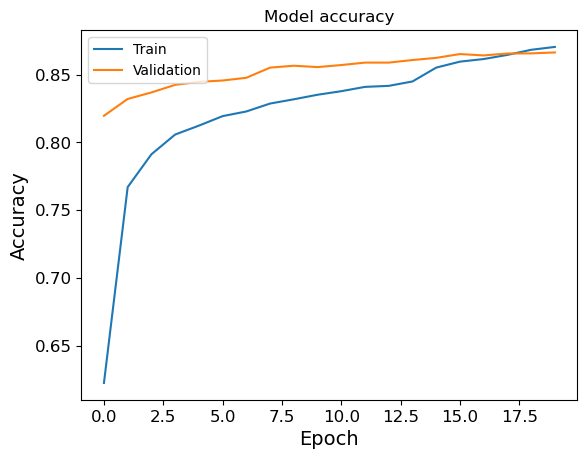

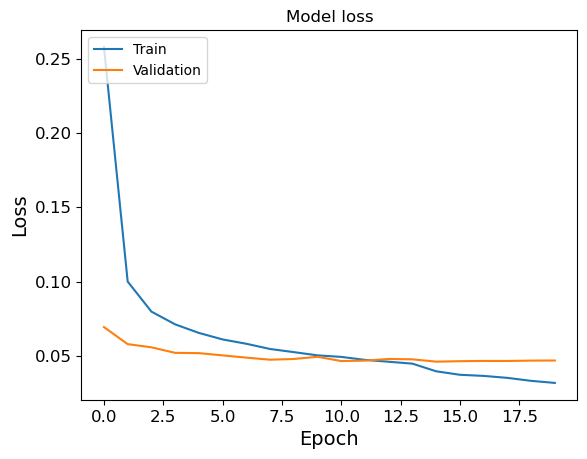

In [178]:
# Visualize training history
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Model accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper left')
plt.show()

plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper left')
plt.show()

In [171]:
# Evaluate the model on test data
test_loss, test_accuracy = model.evaluate(X_test_expanded, y_test)
print(f"Test Accuracy: {test_accuracy:.4f}")

625/625 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8584 - loss: 0.0468
Test Accuracy: 0.8555


In [219]:
# Get predictions
y_pred = model.predict(X_test_expanded)
y_pred_classes = np.argmax(y_pred, axis=1)  # Convert to class labels

# Step 2: Calculate precision and recall
precision = precision_score(y_test, y_pred_classes, average='weighted')  # Use 'weighted' for multi-class
recall = recall_score(y_test, y_pred_classes, average='weighted')

# Step 3: Print the results
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")

625/625 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step
Precision: 0.8398
Recall: 0.8555


/opt/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


# Hyperparameter Tuning

In [208]:
#CNN model
def build_model(hp):
    model = keras.Sequential()
    model.add(keras.Input(shape=(28, 28, 1)))

    # Add convolutional blocks
    for i in range(hp.Int('num_conv_blocks', 1, 4)):
        filters = hp.Int(f'filters_{i}', min_value=32, max_value=256, step=32)
        model.add(keras.layers.Conv2D(filters, kernel_size=(3, 3), activation='relu', padding='same'))
        model.add(keras.layers.BatchNormalization())
        model.add(keras.layers.MaxPooling2D(pool_size=(2, 2)))

    # Flatten and classify
    model.add(keras.layers.Flatten())
    model.add(keras.layers.Dropout(hp.Float('dropout', 0.2, 0.5, step=0.1)))  # Dropout
    model.add(keras.layers.Dense(128, activation='relu'))
    model.add(keras.layers.Dropout(hp.Float('dropout_dense', 0.2, 0.5, step=0.1)))
    model.add(keras.layers.Dense(62, activation='softmax'))  # 62 classes for EMNIST

    # Compile model
    model.compile(
        optimizer=keras.optimizers.Adam(
            learning_rate=hp.Float('learning_rate', 1e-5, 1e-2, sampling='LOG')
        ),
        loss=focal_loss(gamma=2.0, alpha=0.25),  # Use focal loss for class imbalance
        metrics=['accuracy']
    )

    return model

In [210]:
# Create callbacks
early_stopping = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=3)

In [221]:
# Instantiate the Hyperband tuner
tuner = Hyperband(
    build_model,
    objective='val_accuracy',  # Set the objective for optimization
    max_epochs=10,  # Define the max epochs for the search
    factor=3,  # Reduction factor
    directory='emnist_tuning',  # Directory for saving results
    project_name='cnn_trials'  # Project name for clarity
)

# Hyperband tuner search
tuner.search(
    X_train_expanded,
    y_train, 
    validation_data=(X_valid_expanded, y_valid), 
    callbacks=[early_stopping, reduce_lr],
    verbose=1
)

Trial 30 Complete [00h 13m 13s]
val_accuracy: 0.8567000031471252

Best val_accuracy So Far: 0.86080002784729
Total elapsed time: 06h 43m 19s


In [222]:
# Get the best hyperparameters
best_hps = tuner.get_best_hyperparameters(num_trials=1)[0]

# Print the best hyperparameters
print(f"Number of Convolutional Blocks: {best_hps.get('num_conv_blocks')}")
for i in range(best_hps.get('num_conv_blocks')):
    print(f"Filters for Conv Block {i+1}: {best_hps.get(f'filters_{i}')}")
print(f"Dropout Rate for Conv Layers: {best_hps.get('dropout')}")
print(f"Dropout Rate for Dense Layer: {best_hps.get('dropout_dense')}")
print(f"Learning Rate: {best_hps.get('learning_rate')}")

#Build the best model
best_model = tuner.hypermodel.build(best_hps)

Number of Convolutional Blocks: 4
Filters for Conv Block 1: 128
Filters for Conv Block 2: 256
Filters for Conv Block 3: 256
Filters for Conv Block 4: 160
Dropout Rate for Conv Layers: 0.2
Dropout Rate for Dense Layer: 0.4
Learning Rate: 0.00028015930678897556


In [223]:
# Rebuild the final model with best hyperparameters
history = best_model.fit(
    X_train_expanded, y_train,
    epochs=best_hps.get('tuner/epochs'),
    validation_data=(X_valid_expanded, y_valid),
    callbacks=[early_stopping, reduce_lr],
    verbose=1  # Add verbosity for visibility
)

Epoch 1/10
2813/2813 ━━━━━━━━━━━━━━━━━━━━ 246s 87ms/step - accuracy: 0.5806 - loss: 0.3323 - val_accuracy: 0.8296 - val_loss: 0.0666 - learning_rate: 2.8016e-04
Epoch 2/10
2813/2813 ━━━━━━━━━━━━━━━━━━━━ 246s 87ms/step - accuracy: 0.7875 - loss: 0.0897 - val_accuracy: 0.8439 - val_loss: 0.0538 - learning_rate: 2.8016e-04
Epoch 3/10
2813/2813 ━━━━━━━━━━━━━━━━━━━━ 247s 88ms/step - accuracy: 0.8132 - loss: 0.0688 - val_accuracy: 0.8514 - val_loss: 0.0496 - learning_rate: 2.8016e-04
Epoch 4/10
2813/2813 ━━━━━━━━━━━━━━━━━━━━ 247s 88ms/step - accuracy: 0.8274 - loss: 0.0588 - val_accuracy: 0.8547 - val_loss: 0.0494 - learning_rate: 2.8016e-04
Epoch 5/10
2813/2813 ━━━━━━━━━━━━━━━━━━━━ 251s 89ms/step - accuracy: 0.8384 - loss: 0.0518 - val_accuracy: 0.8559 - val_loss: 0.0470 - learning_rate: 2.8016e-04
Epoch 6/10
2813/2813 ━━━━━━━━━━━━━━━━━━━━ 251s 89ms/step - accuracy: 0.8468 - loss: 0.0471 - val_accuracy: 0.8584 - val_loss: 0.0474 - learning_rate: 2.8016e-04
Epoch 7/10
2813/2813 ━━━━━━━━━━━━━

In [224]:
# Evaluate the model on test data
test_loss, test_accuracy = best_model.evaluate(X_test_expanded, y_test)
print(f"Test Accuracy: {test_accuracy:.4f}")

625/625 ━━━━━━━━━━━━━━━━━━━━ 13s 21ms/step - accuracy: 0.8600 - loss: 0.0448
Test Accuracy: 0.8601


In [229]:
# Get predictions
y_pred = best_model.predict(X_test_expanded)
y_pred_classes = np.argmax(y_pred, axis=1)  # Convert to class labels

# Step 2: Calculate precision and recall
precision = precision_score(y_test, y_pred_classes, average='weighted')  # Use 'weighted' for multi-class
recall = recall_score(y_test, y_pred_classes, average='weighted')

# Step 3: Print the results
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")

625/625 ━━━━━━━━━━━━━━━━━━━━ 11s 17ms/step
Precision: 0.8485
Recall: 0.8601


/opt/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


# Model 2 [MLP]

In [13]:
# Define MLP layer by layer
model = keras.models.Sequential([
    keras.layers.Flatten(input_shape=[28, 28]),  # Flatten the input (28x28 -> 784)
    
    keras.layers.Dense(512, activation='relu'),  # Hidden layer 1
    keras.layers.Dropout(0.2),  # Dropout for regularization

    keras.layers.Dense(256, activation='relu'),  # Hidden layer 2
    keras.layers.Dropout(0.2),  # Dropout for regularization

    keras.layers.Dense(128, activation='relu'),  # Hidden layer 3

    keras.layers.Dense(62, activation='softmax')  # Output layer (62 classes)
])

model.summary()

/opt/anaconda3/lib/python3.12/site-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │       401,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 62)             │         7,998 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 574,142 (2.19 MB)

 Trainable params: 574,142 (2.19 MB)

 Non-trainable params: 0 (0.00 B)

The first layer flattens the 28*28 2D input images to 1D with 784 values. The model has three hidden layers with 512,256 and 128 nuerons, each using relu activation function. Dropout(0.2) has been applied after first two layers to reduce overfitting. The output layer has 62 nuerons with softmax activation function.

### Specifying the Optimiser and Loss Function

In [15]:
# Instantiate optimiser and compile the model.
opt = keras.optimizers.Adam(learning_rate=0.0005)
model.compile(loss='sparse_categorical_crossentropy',
              optimizer=opt,
              metrics=['accuracy'])

We have used the Adam learning algorithm with a learnong rate of 0.0005. We have also used the sparse_categorical_crossentropy loss. Here, out metric of interest is accuracy, therefore that will be reported during training.

### Using EarlyStopping

In [17]:
early_stopping = keras.callbacks.EarlyStopping(
    monitor='val_loss', patience=5, restore_best_weights=True)

The EarlyStopping callback will monitor the validation loss during training and stop the training process if the validation loss does not imporove for 5 consecutive epochs and also restore the best model weights to prevent overfitting.

### Training and Evaluating the Model

In [19]:
# Train the classifier.
history = model.fit(X_train, y_train, epochs=30, validation_data=(X_valid, y_valid), 
    callbacks=[early_stopping])

Epoch 1/30
2813/2813 ━━━━━━━━━━━━━━━━━━━━ 13s 4ms/step - accuracy: 0.5853 - loss: 1.5561 - val_accuracy: 0.7748 - val_loss: 0.6952
Epoch 2/30
2813/2813 ━━━━━━━━━━━━━━━━━━━━ 12s 4ms/step - accuracy: 0.7644 - loss: 0.7291 - val_accuracy: 0.8025 - val_loss: 0.5982
Epoch 3/30
2813/2813 ━━━━━━━━━━━━━━━━━━━━ 11s 4ms/step - accuracy: 0.7891 - loss: 0.6243 - val_accuracy: 0.8153 - val_loss: 0.5610
Epoch 4/30
2813/2813 ━━━━━━━━━━━━━━━━━━━━ 11s 4ms/step - accuracy: 0.8057 - loss: 0.5680 - val_accuracy: 0.8162 - val_loss: 0.5490
Epoch 5/30
2813/2813 ━━━━━━━━━━━━━━━━━━━━ 11s 4ms/step - accuracy: 0.8134 - loss: 0.5376 - val_accuracy: 0.8250 - val_loss: 0.5275
Epoch 6/30
2813/2813 ━━━━━━━━━━━━━━━━━━━━ 11s 4ms/step - accuracy: 0.8219 - loss: 0.5061 - val_accuracy: 0.8250 - val_loss: 0.5236
Epoch 7/30
2813/2813 ━━━━━━━━━━━━━━━━━━━━ 11s 4ms/step - accuracy: 0.8269 - loss: 0.4873 - val_accuracy: 0.8301 - val_loss: 0.5170
Epoch 8/30
2813/2813 ━━━━━━━━━━━━━━━━━━━━ 11s 4ms/step - accuracy: 0.8322 - loss: 0

Calling the fit method returns a dictionary of the training history, which we will utilise to visualise the change in training and validation accuracy over time.

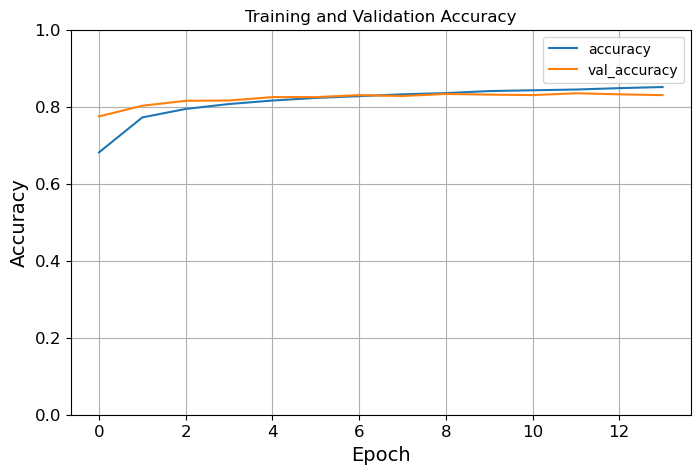

In [20]:
# Convert the history dictionary to a DataFrame and extract accuracies
history_df = pd.DataFrame(history.history)

accuracies = history_df[['accuracy', 'val_accuracy']]
accuracies.plot(figsize=(8, 5))
plt.grid(True)
plt.gca().set_ylim(0.0, 1.0)  # Adjust the y-axis range
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Training and Validation Accuracy')
plt.show()

The training history has been converted into a DataFrame which is then used to plot the training and validation accuracies over epochs to visualize the model's performance during training. 

### Test Set Accuracy

In [21]:
# Evaluate the classifier on the test data.
loss, accuracy = model.evaluate(X_test, y_test)
print(f"Accuracy on test data: {accuracy:.4f}")

625/625 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8286 - loss: 0.5140
Accuracy on test data: 0.8280


To ultimately check the model's generalisation ability, it has been evaluated on the test set, which had no influence in the training process; resulting in an accuracy of 82.54%.

## Performance of the Model

In [22]:
y_pred_prob = model.predict(X_test)

y_pred = np.argmax(y_pred_prob, axis=1)

precision = precision_score(y_test, y_pred, average='macro') 
recall = recall_score(y_test, y_pred, average='macro')

print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")

625/625 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step
Precision: 0.7197
Recall: 0.6744


/opt/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1509: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


## Hyperparmeter Tuning

### Building a Keras Model

In [23]:
def build_mlp(
    n_hidden_layers=2, 
    n_hidden_neurons=50,
    activation_function="relu", 
    optimizer_name="adam", 
    optimizer_lr=0.001, 
    input_shape=(28, 28)
):
    model = keras.models.Sequential()

    # Add the input layer
    model.add(keras.layers.Flatten(input_shape=input_shape))

    for layer in range(n_hidden_layers):
        model.add(keras.layers.Dense(n_hidden_neurons, activation=activation_function))

    model.add(keras.layers.Dense(62, activation="softmax"))

    if optimizer_name == "sgd":
        optimizer = SGD(learning_rate=optimizer_lr)
    elif optimizer_name == "adam":
        optimizer = Adam(learning_rate=optimizer_lr)
    else:
        raise ValueError("Unsupported optimizer: Choose 'sgd' or 'adam'")

    model.compile(optimizer=optimizer, 
                  loss="sparse_categorical_crossentropy", 
                  metrics=["accuracy"])

    return model

Here, we build an MLP Model with variable number of hidden layers and neurons, using relu as default activation function and optimizer (Adam or SGD). We have flattened the input, added hidden layers, and used a 62-class softmax output layer for classification. The model is compiled with sparse categorical crossentropy loss and accuracy as the evaluation metric.

### Using sklearn grid searches with Keras Model

In [24]:
keras_classifier = KerasClassifier(
    model=build_mlp, 
    verbose=0
)

The build_mlp function has been wrapped inside KerasClassifier, allowing it to work with GridSearchCV for hyperparameter tuning.

### Using GridSearchCV

In [25]:
param_grid = {
    "model__n_hidden_layers": [1, 2],
    "model__n_hidden_neurons": [100, 200],
    "model__activation_function": ["relu", "sigmoid", "tanh"],
    "model__optimizer_name": ["adam", "sgd"],
    "model__optimizer_lr": [0.01, 0.001, 0.0001]
}

# Set up GridSearchCV
grid_search_cv = GridSearchCV(
    estimator=keras_classifier,
    param_grid=param_grid,
    cv=3,
    verbose=2
)

# Fit the model using GridSearchCV
grid_search_cv.fit(X_train, y_train)

Fitting 3 folds for each of 72 candidates, totalling 216 fits


/opt/anaconda3/lib/python3.12/site-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


[CV] END model__activation_function=relu, model__n_hidden_layers=1, model__n_hidden_neurons=100, model__optimizer_lr=0.01, model__optimizer_name=adam; total time=   2.9s


/opt/anaconda3/lib/python3.12/site-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


[CV] END model__activation_function=relu, model__n_hidden_layers=1, model__n_hidden_neurons=100, model__optimizer_lr=0.01, model__optimizer_name=adam; total time=   2.7s


/opt/anaconda3/lib/python3.12/site-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


... (425 outputs left out)

/opt/anaconda3/lib/python3.12/site-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


[CV] END model__activation_function=tanh, model__n_hidden_layers=2, model__n_hidden_neurons=200, model__optimizer_lr=0.0001, model__optimizer_name=sgd; total time=   2.9s


/opt/anaconda3/lib/python3.12/site-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


GridSearchCV(cv=3,
             estimator=KerasClassifier(model=<function build_mlp at 0x306e22d40>, verbose=0),
             param_grid={'model__activation_function': ['relu', 'sigmoid',
                                                        'tanh'],
                         'model__n_hidden_layers': [1, 2],
                         'model__n_hidden_neurons': [100, 200],
                         'model__optimizer_lr': [0.01, 0.001, 0.0001],
                         'model__optimizer_name': ['adam', 'sgd']},
             verbose=2)

GridSearchCV has been used with 3-fold-cross-validation to find the best parameters for the MLP Model wrapped in the keras_classifier. The param_grid defines the possible values for the number of hidden layers, neurons, activation functions, optimizers, and learning rates. At the end, the training data has been fit with the model using grid_search_cv.fit.

### Getting the best parameters

In [26]:
# Get the best parameters from the grid search
best_params = grid_search_cv.best_params_
print("Best Parameters:", best_params)

# Get the best estimator (model with best hyperparameters)
best_model = grid_search_cv.best_estimator_
print("Best Estimator:", best_model)


Best Parameters: {'model__activation_function': 'relu', 'model__n_hidden_layers': 2, 'model__n_hidden_neurons': 200, 'model__optimizer_lr': 0.001, 'model__optimizer_name': 'adam'}
Best Estimator: KerasClassifier(
	model=<function build_mlp at 0x306e22d40>
	build_fn=None
	warm_start=False
	random_state=None
	optimizer=rmsprop
	loss=None
	metrics=None
	batch_size=None
	validation_batch_size=None
	verbose=0
	callbacks=None
	validation_split=0.0
	shuffle=True
	run_eagerly=False
	epochs=1
	class_weight=None
	model__activation_function=relu
	model__n_hidden_layers=2
	model__n_hidden_neurons=200
	model__optimizer_lr=0.001
	model__optimizer_name=adam
)


### Finding the test accuracy with the best parameters

In [27]:
# Extract the individual parameters
n_hidden_layers = best_params["model__n_hidden_layers"]
n_hidden_neurons = best_params["model__n_hidden_neurons"]
activation_function = best_params["model__activation_function"]
optimizer_name = best_params["model__optimizer_name"]
optimizer_lr = best_params["model__optimizer_lr"]

# Build the model with the best parameters
best_model = build_mlp(
    n_hidden_layers=n_hidden_layers,
    n_hidden_neurons=n_hidden_neurons,
    activation_function=activation_function,

    optimizer_name=optimizer_name,
    optimizer_lr=optimizer_lr,
    input_shape=(28, 28)
)

# Train the best model on the entire training data
history = best_model.fit(
    X_train, y_train,
    epochs=20,  
    batch_size=32,  
    validation_data=(X_valid, y_valid),  
    verbose=1
)

# Evaluate the best model on test data
test_loss, test_accuracy = best_model.evaluate(X_test, y_test, verbose=0)
print(f"Test Accuracy: {test_accuracy:.4f}")


Epoch 1/20


/opt/anaconda3/lib/python3.12/site-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


2813/2813 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.6445 - loss: 1.3133 - val_accuracy: 0.7831 - val_loss: 0.6726
Epoch 2/20
2813/2813 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.7900 - loss: 0.6371 - val_accuracy: 0.8037 - val_loss: 0.6058
Epoch 3/20
2813/2813 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.8154 - loss: 0.5408 - val_accuracy: 0.8023 - val_loss: 0.6004
Epoch 4/20
2813/2813 ━━━━━━━━━━━━━━━━━━━━ 6s 2ms/step - accuracy: 0.8307 - loss: 0.4855 - val_accuracy: 0.8036 - val_loss: 0.6086
Epoch 5/20
2813/2813 ━━━━━━━━━━━━━━━━━━━━ 6s 2ms/step - accuracy: 0.8415 - loss: 0.4445 - val_accuracy: 0.8047 - val_loss: 0.6136
Epoch 6/20
2813/2813 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.8501 - loss: 0.4115 - val_accuracy: 0.8012 - val_loss: 0.6386
Epoch 7/20
2813/2813 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.8586 - loss: 0.3859 - val_accuracy: 0.8073 - val_loss: 0.6532
Epoch 8/20
2813/2813 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.8624 - loss: 0.3654 - val_accurac

The best hyperparameters have been retrieved from GridSearchCV to rebuild the MLP model using those parameters. The model has been trained on the traing data with specified epochs and batch size. Finally, the trained model has been evaluated on the test set, with the test accuracy resulting as 79.29%.

## Performance of the Model after Hyperparameter Tuning

In [28]:
y_pred_prob = best_model.predict(X_test)  
y_pred = np.argmax(y_pred_prob, axis=1)   

precision = precision_score(y_test, y_pred, average='weighted')  # Weighted avg for multiclass
recall = recall_score(y_test, y_pred, average='weighted')
f1 = f1_score(y_test, y_pred, average='weighted')

print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1 Score: {f1:.4f}")

print("\nClassification Report:\n", classification_report(y_test, y_pred))


625/625 ━━━━━━━━━━━━━━━━━━━━ 0s 580us/step
Precision: 0.7833
Recall: 0.7829
F1 Score: 0.7783

Classification Report:
               precision    recall  f1-score   support

           0       0.63      0.75      0.68       976
           1       0.65      0.87      0.74      1023
           2       0.93      0.93      0.93      1003
           3       0.97      0.95      0.96      1035
           4       0.96      0.88      0.92       903
           5       0.85      0.85      0.85       928
           6       0.91      0.95      0.93       959
           7       0.95      0.97      0.96      1098
           8       0.90      0.93      0.92       941
           9       0.91      0.83      0.87       929
          10       0.88      0.85      0.87       170
          11       0.73      0.58      0.65       118
          12       0.76      0.77      0.76       316
          13       0.69      0.72      0.70       128
          14       0.83      0.87      0.85       162
          15     

# Model3 [LeNet-5]

### Define the LeNet-5 model

In [61]:
# Define the LeNet-5 model
class LeNet5(nn.Module):
    def __init__(self):
        super(LeNet5, self).__init__()
        self.conv1 = nn.Conv2d(1, 6, kernel_size=5)  # Input: (1, 28, 28), Output: (6, 24, 24)
        self.pool1 = nn.AvgPool2d(2, stride=2)      # Output: (6, 12, 12)
        self.conv2 = nn.Conv2d(6, 16, kernel_size=5)  # Output: (16, 8, 8)
        self.pool2 = nn.AvgPool2d(2, stride=2)      # Output: (16, 4, 4)
        self.fc1 = nn.Linear(16 * 4 * 4, 120)
        self.fc2 = nn.Linear(120, 84)
        self.fc3 = nn.Linear(84, 62)  # 62 classes for EMNIST by_class

    def forward(self, x):
        x = torch.relu(self.conv1(x))
        x = self.pool1(x)
        x = torch.relu(self.conv2(x))
        x = self.pool2(x)
        x = x.view(-1, 16 * 4 * 4)  # Flatten the tensor
        x = torch.relu(self.fc1(x))
        x = torch.relu(self.fc2(x))
        x = self.fc3(x)
        return x

In [11]:
# Instantiate the model, define the loss function and optimizer
model = LeNet5()
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

In [13]:
# Check for GPU availability
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = model.to(device)

In [15]:
train_time=[]

In [21]:
# Training loop
num_epochs = 10
for epoch in range(num_epochs):
    start_time=time.time()
    model.train()
    running_loss = 0.0
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        
        # Zero the parameter gradients
        optimizer.zero_grad()
        
        # Forward pass
        outputs = model(images)
        loss = criterion(outputs, labels)
        
        # Backward pass and optimize
        loss.backward()
        optimizer.step()
        
        running_loss += loss.item()
    end_time=time.time()
    train_time.append(end_time-start_time)
    print(f'Epoch [{epoch + 1}/{num_epochs}], Loss: {running_loss / len(train_loader):.4f}')


Epoch [1/10], Loss: 1.2631
Epoch [2/10], Loss: 0.6948
Epoch [3/10], Loss: 0.5940
Epoch [4/10], Loss: 0.5415
Epoch [5/10], Loss: 0.5077
Epoch [6/10], Loss: 0.4830
Epoch [7/10], Loss: 0.4636
Epoch [8/10], Loss: 0.4477
Epoch [9/10], Loss: 0.4352
Epoch [10/10], Loss: 0.4233


In [23]:
print(train_time)

[17.713685989379883, 12.016218185424805, 17.070361375808716, 16.61068820953369, 11.926936864852905, 16.2072536945343, 16.002477884292603, 11.51882028579712, 9.718137264251709, 11.050542831420898]


In [25]:
# Evaluate the model on the test set
model.eval()
correct = 0
total = 0
with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

accuracy = 100 * correct / total
print(f'Test Accuracy: {accuracy:.2f}%')

# Save the trained model
torch.save(model.state_dict(), 'lenet5_emnist.pth')
print('Model saved as lenet5_emnist.pth')

Test Accuracy: 83.14%
Model saved as lenet5_emnist.pth


### Hyperparameter tune

In [29]:
#tune the hyper parameter by Grid Search
gs_model = NeuralNetClassifier(
    LeNet5,
    max_epochs=10,
    lr=0.001,
    optimizer=optim.Adam,
    criterion=nn.CrossEntropyLoss,
    batch_size=64,
    device='cuda' if torch.cuda.is_available() else 'cpu',  # GPU if available
)


In [31]:
# Define the grid of hyperparameters
params = {
    'lr': [0.001, 0.0001],               # Different learning rates
    'optimizer': [optim.Adam, optim.SGD], # Try different optimizers
    'max_epochs': [10, 20, 30],               # Number of epochs
}

In [33]:
# Perform the grid search

gs = GridSearchCV(gs_model, params, refit=True, cv=3, scoring='accuracy', verbose=2)
start_time=time.time()
gs.fit(train_images, train_labels)
end_time=time.time()

gs_train_time=end_time-start_time
# Get the best parameters
print("Train time: ", gs_train_time)
print("Best hyperparameters found: ", gs.best_params_)

Fitting 3 folds for each of 12 candidates, totalling 36 fits
  epoch    train_loss    valid_acc    valid_loss      dur
-------  ------------  -----------  ------------  -------
      1        1.5574       0.7244        0.8986  10.0998
      2        0.7994       0.7690        0.7259  7.9207
      3        0.6755       0.7888        0.6486  8.4639
      4        0.6101       0.8004        0.5995  6.6760
      5        0.5670       0.8067        0.5699  8.0990
      6        0.5348       0.8109        0.5543  7.9926
      7        0.5090       0.8164        0.5383  7.5312
      8        0.4893       0.8199        0.5294  6.8283
      9        0.4720       0.8193        0.5263  7.6900
     10        0.4562       0.8201        0.5259  8.0686
[CV] END lr=0.001, max_epochs=10, optimizer=<class 'torch.optim.adam.Adam'>; total time= 1.4min
  epoch    train_loss    valid_acc    valid_loss     dur
-------  ------------  -----------  ------------  ------
      1        1.5968       0.7131        

In [35]:
print("best approach accuracy: ", gs.best_score_)

best approach accuracy:  0.8079299092624934


In [45]:
# Save the trained model
best_model = gs.best_estimator_
torch.save(best_model.module_.state_dict(), 'lenet5_emnist_tune1.pth')

Model saved as lenet5_emnist.pth


In [ ]:
#reload the model
model = LeNet5()
model.load_state_dict(torch.load('lenet5_emnist_tune1.pth'))


In [47]:
gs_model = NeuralNetClassifier(
    LeNet5,
    max_epochs=20,
    lr=0.0001,
    optimizer=optim.Adam,
    criterion=nn.CrossEntropyLoss,
    batch_size=64,
    device='cuda' if torch.cuda.is_available() else 'cpu',  # GPU if available
)


In [117]:
#by above result we can find that adam is much better than SGD
params = {
    'lr': [0.0008, 0.0007, 0.0006],               # Different learning rates
    'max_epochs': [19, 20, 21],               # Number of epochs
}

In [119]:
gs = GridSearchCV(gs_model, params, refit=True, cv=3, scoring='accuracy', verbose=2)
start_time=time.time()
gs.fit(train_images, train_labels)
end_time=time.time()

gs_train_time=end_time-start_time
# Get the best parameters
print("Train time: ", gs_train_time)
print("Best hyperparameters found: ", gs.best_params_)

Fitting 3 folds for each of 9 candidates, totalling 27 fits
  epoch    train_loss    valid_acc    valid_loss      dur
-------  ------------  -----------  ------------  -------
      1        1.6440       0.7005        0.9756  11.0184
      2        0.8486       0.7601        0.7594  11.0869
      3        0.7022       0.7836        0.6709  11.7049
      4        0.6260       0.7956        0.6187  9.8957
      5        0.5775       0.8027        0.5863  11.3400
      6        0.5448       0.8071        0.5646  9.1748
      7        0.5181       0.8118        0.5511  9.2028
      8        0.4971       0.8149        0.5419  9.1640
      9        0.4789       0.8169        0.5372  10.3944
     10        0.4629       0.8193        0.5353  8.5862
     11        0.4491       0.8214        0.5334  8.9583
     12        0.4371       0.8191        0.5341  9.1552
     13        0.4260       0.8193        0.5346  7.6670
     14        0.4155       0.8205        0.5372  6.6589
     15        0.4059

In [121]:
print("best approach accuracy: ", gs.best_score_)

best approach accuracy:  0.8106098790633314


In [123]:
# Save the trained model
best_model = gs.best_estimator_.module_
torch.save(best_model.state_dict(), 'lenet5_emnist_tune2.pth')


In [125]:
# Evaluate the model on the test set
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
best_model.eval()
correct = 0
total = 0
with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = best_model(images)
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

accuracy = 100 * correct / total
print(f'Test Accuracy: {accuracy:.2f}%')

Test Accuracy: 83.01%


### Retrain the model by the best Hyperparameter we got

In [65]:
#by the hyper paremeter we get re train
#Best hyperparameters found:  {'lr': 0.0005, 'max_epochs': 20, 'optimizer': <class 'torch.optim.adam.Adam'>} #optimizer is set default
final_model = LeNet5()
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(final_model.parameters(), lr=0.0008)
num_epochs = 20

final_model = final_model.to(device)
train_time=[]

In [67]:
# Training loop
for epoch in range(num_epochs):
    start_time=time.time()
    final_model.train()
    running_loss = 0.0
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        
        # Zero the parameter gradients
        optimizer.zero_grad()
        
        # Forward pass
        outputs = final_model(images)
        loss = criterion(outputs, labels)
        
        # Backward pass and optimize
        loss.backward()
        optimizer.step()
        
        running_loss += loss.item()
    end_time=time.time()
    train_time.append(end_time-start_time)
    print(f'Epoch [{epoch + 1}/{num_epochs}], Loss: {running_loss / len(train_loader):.4f}')


Epoch [1/20], Loss: 1.2921
Epoch [2/20], Loss: 0.6941
Epoch [3/20], Loss: 0.5937
Epoch [4/20], Loss: 0.5382
Epoch [5/20], Loss: 0.5057
Epoch [6/20], Loss: 0.4795
Epoch [7/20], Loss: 0.4610
Epoch [8/20], Loss: 0.4460
Epoch [9/20], Loss: 0.4327
Epoch [10/20], Loss: 0.4221
Epoch [11/20], Loss: 0.4119
Epoch [12/20], Loss: 0.4039
Epoch [13/20], Loss: 0.3956
Epoch [14/20], Loss: 0.3883
Epoch [15/20], Loss: 0.3825
Epoch [16/20], Loss: 0.3752
Epoch [17/20], Loss: 0.3693
Epoch [18/20], Loss: 0.3646
Epoch [19/20], Loss: 0.3590
Epoch [20/20], Loss: 0.3542


In [69]:
print(train_time)

[8.054076433181763, 7.344969272613525, 6.958734035491943, 6.754415273666382, 6.238702297210693, 6.477055788040161, 6.343416929244995, 6.46470308303833, 6.221763610839844, 6.147729873657227, 6.364074945449829, 6.676672697067261, 6.642068386077881, 7.919597625732422, 7.218350172042847, 6.934588670730591, 6.64347243309021, 6.477947235107422, 6.644627809524536, 6.735281229019165]


In [71]:
# Save the trained model
torch.save(final_model.state_dict(), 'lenet5_emnist_final.pth')

### Evaluate the Model

In [23]:
#reload the model
final_model = LeNet5()
final_model.load_state_dict(torch.load('lenet5_emnist_final.pth'))
final_model.to(device)

C:\Users\58305\AppData\Local\Temp\ipykernel_20880\3247826291.py:3: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  final_model.load_state_dict(torch.load('lenet5_emnist_final.

LeNet5(
  (conv1): Conv2d(1, 6, kernel_size=(5, 5), stride=(1, 1))
  (pool1): AvgPool2d(kernel_size=2, stride=2, padding=0)
  (conv2): Conv2d(6, 16, kernel_size=(5, 5), stride=(1, 1))
  (pool2): AvgPool2d(kernel_size=2, stride=2, padding=0)
  (fc1): Linear(in_features=256, out_features=120, bias=True)
  (fc2): Linear(in_features=120, out_features=84, bias=True)
  (fc3): Linear(in_features=84, out_features=62, bias=True)
)

In [31]:
# Collect true labels and predictions
all_labels = []
all_predictions = []

# Initialize counters for accuracy
correct = 0
total = 0

# Start evaluating the model on the test set
final_model.eval()
with torch.no_grad():
    start_time = time.time()  # Start the time for prediction time
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = final_model(images)
        
        # Get predictions
        _, predicted = torch.max(outputs.data, 1)
        
        # Calculate total and correct for accuracy
        total += labels.size(0)
        correct += (predicted == labels).sum().item()
        
        # Store the labels and predictions for classification report (precision, recall, etc.)
        all_labels.extend(labels.cpu().numpy())
        all_predictions.extend(predicted.cpu().numpy())
    
    end_time = time.time()  # End the timer for prediction

# Calculate accuracy
accuracy = 100 * correct / total
print(f'Test Accuracy: {accuracy:.2f}%')

# Calculate precision, recall, and other metrics using sklearn's classification_report
print(classification_report(all_labels, all_predictions, target_names=[str(i) for i in range(62)]))

# Optionally, print the prediction time
print(f'Prediction time: {end_time - start_time:.2f} seconds')


Test Accuracy: 84.32%
              precision    recall  f1-score   support

           0       0.66      0.82      0.73       976
           1       0.67      0.90      0.77      1023
           2       0.95      0.94      0.95      1003
           3       0.99      0.98      0.98      1035
           4       0.96      0.96      0.96       903
           5       0.91      0.92      0.91       928
           6       0.95      0.98      0.96       959
           7       0.98      0.99      0.98      1098
           8       0.96      0.97      0.96       941
           9       0.93      0.95      0.94       929
          10       0.93      0.92      0.92       170
          11       0.85      0.84      0.85       118
          12       0.74      0.95      0.83       316
          13       0.89      0.85      0.87       128
          14       0.93      0.95      0.94       162
          15       0.82      0.92      0.87       261
          16       0.83      0.75      0.79        60
     

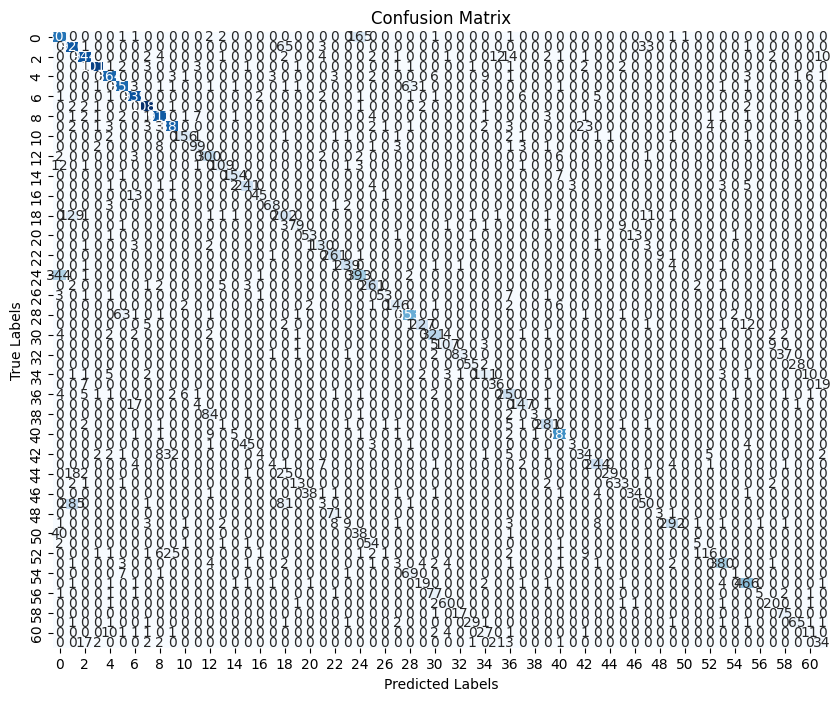

In [77]:
import torch
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Collect the true and predicted labels
all_labels = []
all_preds = []

# Evaluate the model on the test set and collect predictions
final_model.eval()
with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = final_model(images)
        _, predicted = torch.max(outputs.data, 1)
        
        all_labels.extend(labels.cpu().numpy())
        all_preds.extend(predicted.cpu().numpy())

# Compute the confusion matrix
conf_matrix = confusion_matrix(all_labels, all_preds)

# Plot the confusion matrix
plt.figure(figsize=(10, 8))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()